# EDA – Candidate Profiles

Erster Überblick über den Djinni-Kandidat:innen-Datensatz (`data/raw/djinni/cv_profiles_en.parquet`).

Ziel dieses Notebooks: Struktur, Vollständigkeit und Verteilungen der Rohdaten verstehen, bevor Cleaning / Feature Engineering / Bias-Analysen aufgesetzt werden.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("../data/raw/djinni/cv_profiles_en.parquet")

# Farb-/Stilkonstanten (konsistent für alle Plots in diesem Notebook)
BLUE = "#2a78d6"
BLUE_ORDINAL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 10,
})

## 1. Daten laden

In [2]:
cv = pd.read_parquet(DATA_PATH)
print(f"Zeilen: {len(cv):,} | Spalten: {cv.shape[1]}")
cv.dtypes

Zeilen: 210,250 | Spalten: 11


Position                 str
Moreinfo                 str
Looking For              str
Highlights               str
Primary Keyword          str
English Level            str
Experience Years     float64
CV                       str
CV_lang                  str
id                       str
__index_level_0__      int64
dtype: object

## 2. Erster Blick

Stichprobe der Rohdaten, um Struktur und Freitext-Felder zu sehen.

In [3]:
cv.head(3)

,Position,Moreinfo,Looking For,Highlights,Primary Keyword,English Level,Experience Years,CV,CV_lang,id,__index_level_0__
0,"13 years of exp || Solidity, C#, JavaScript ||...",Who am I:\r\n- 13 years of commercial experien...,I am interested in:\r\n- part-time engagement;...,Landed a role of Director of Blockchain Develo...,Lead,fluent,11.0,Landed a role of Director of Blockchain Develo...,en,50534b61-6826-52b1-9ac5-bfd2cfa348ec,24230
1,1c Developer,Worked on a mobile application for tracking trips,NaN,NaN,Other,intermediate,3.0,\nWorked on a mobile application for tracking ...,en,c2b9ea56-b5c8-50ec-a63b-053a5c8ff467,24231
2,1C developer,1 am an 1C developer. I deployed an 1C to typo...,NaN,NaN,Flutter,intermediate,11.0,\n1 am an 1C developer. I deployed an 1C to ty...,en,b3bfe3ed-ec25-56b2-8aaa-8c629120538e,24232


In [4]:
cv.sample(3, random_state=42)[["Position", "Primary Keyword", "Experience Years", "English Level"]]

,Position,Primary Keyword,Experience Years,English Level
207440,Разработчик java,Java,9.0,upper
36952,Front-end developer,JavaScript,0.0,intermediate
16095,C# .NET Core Developer,.NET,0.0,upper


## 3. Fehlende Werte

`Looking For` und `Highlights` sind optionale Freitext-Felder von Kandidat:innen – hohe Missing-Rate ist hier erwartbar. `Primary Keyword` und `English Level` sollten dagegen fast vollständig sein.

In [5]:
missing = cv.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(cv) * 100).round(1)
missing_df = pd.DataFrame({"missing": missing, "pct": missing_pct})
missing_df = missing_df[missing_df["missing"] > 0]
missing_df

,missing,pct
Looking For,108195,51.5
Highlights,104721,49.8
English Level,485,0.2
Primary Keyword,43,0.0


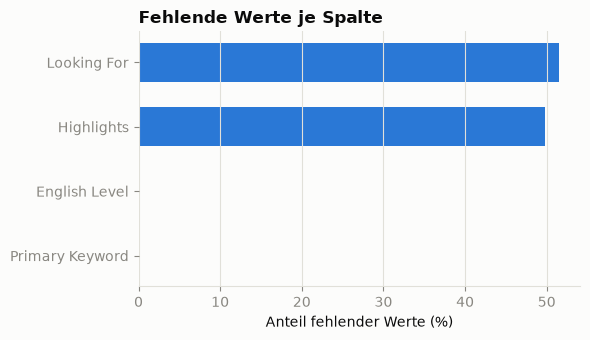

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(missing_df.index[::-1], missing_df["pct"][::-1], color=BLUE, height=0.6)
ax.set_xlabel("Anteil fehlender Werte (%)")
ax.set_title("Fehlende Werte je Spalte", loc="left", color=INK, fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 4. Primary Keyword (Rolle / Tech-Stack)

Häufigste Kategorien, denen Kandidat:innen zugeordnet sind.

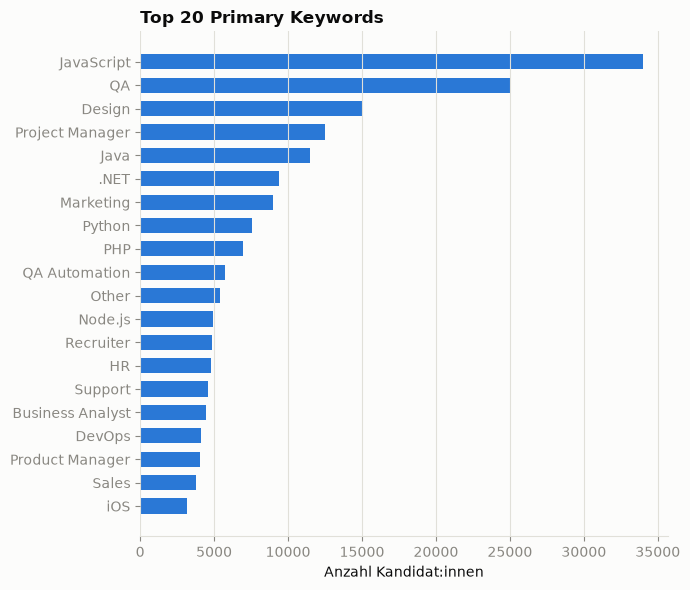

Anzahl unterschiedlicher Keywords: 41


In [7]:
top_keywords = cv["Primary Keyword"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top_keywords.index[::-1], top_keywords.values[::-1], color=BLUE, height=0.65)
ax.set_xlabel("Anzahl Kandidat:innen")
ax.set_title("Top 20 Primary Keywords", loc="left", color=INK, fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"Anzahl unterschiedlicher Keywords: {cv['Primary Keyword'].nunique()}")

## 5. Berufserfahrung (Experience Years)

In [8]:
cv["Experience Years"].describe()

count    210250.000000
mean          3.836901
std           3.291261
min           0.000000
25%           1.000000
50%           3.000000
75%           6.000000
max          11.000000
Name: Experience Years, dtype: float64

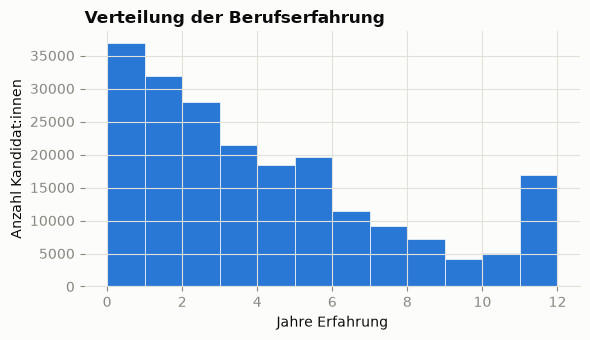

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(cv["Experience Years"], bins=range(0, 13), color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.set_xlabel("Jahre Erfahrung")
ax.set_ylabel("Anzahl Kandidat:innen")
ax.set_title("Verteilung der Berufserfahrung", loc="left", color=INK, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Englischkenntnisse

Geordnete (ordinale) Kategorie – daher ein abgestufter Blauton statt unterschiedlicher Farben je Kategorie.

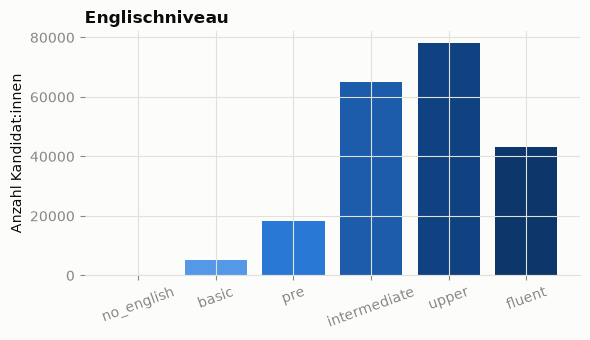

In [10]:
level_order = ["no_english", "basic", "pre", "intermediate", "upper", "fluent"]
level_counts = cv["English Level"].value_counts().reindex(level_order)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(level_counts.index, level_counts.values, color=BLUE_ORDINAL[:len(level_order)])
ax.set_ylabel("Anzahl Kandidat:innen")
ax.set_title("Englischniveau", loc="left", color=INK, fontweight="bold")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 7. CV-Textlänge

Länge des Freitext-Lebenslaufs (Feld `CV`) als grobes Signal für Informationsgehalt / Datenqualität.

In [11]:
cv_len_chars = cv["CV"].str.len()
cv_len_words = cv["CV"].str.split().str.len()

pd.DataFrame({"chars": cv_len_chars, "words": cv_len_words}).describe()

,chars,words
count,210250.000000,210250.000000
mean,944.351505,138.170740
std,677.435931,98.551079
min,6.000000,1.000000
25%,454.000000,67.000000
50%,751.000000,110.000000
75%,1235.000000,181.000000
max,7372.000000,1061.000000


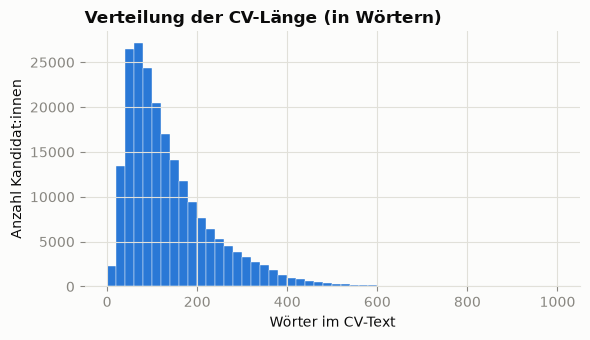

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(cv_len_words, bins=50, range=(0, 1000), color=BLUE, edgecolor=SURFACE, linewidth=0.3)
ax.set_xlabel("Wörter im CV-Text")
ax.set_ylabel("Anzahl Kandidat:innen")
ax.set_title("Verteilung der CV-Länge (in Wörtern)", loc="left", color=INK, fontweight="bold")
plt.tight_layout()
plt.show()

## 8. Duplikate & Datenqualität

In [13]:
n_dup_ids = cv["id"].duplicated().sum()
n_dup_cv_text = cv["CV"].duplicated().sum()

print(f"Duplizierte IDs: {n_dup_ids}")
print(f"Duplizierte CV-Texte (identischer Volltext): {n_dup_cv_text}")
print(f"Kandidat:innen ohne 'Primary Keyword': {cv['Primary Keyword'].isna().sum()}")

Duplizierte IDs: 0
Duplizierte CV-Texte (identischer Volltext): 0
Kandidat:innen ohne 'Primary Keyword': 43


## 9. Zusammenfassung – erste Beobachtungen

- **Umfang:** ~210k Kandidatenprofile, ausschließlich englischsprachig (`CV_lang == "en"`).
- **Fehlende Werte:** `Looking For` (~51%) und `Highlights` (~50%) sind optionale Felder – erwartbar. `Primary Keyword` (43 fehlende) und `English Level` (485 fehlende) sind nahezu vollständig.
- **Primary Keyword:** stark Tech-lastig (JavaScript, QA, Java, .NET, Python vorne) – bei Bias-Analysen auf Klassenungleichgewicht achten.
- **Erfahrung:** rechtsschief, Median 3 Jahre, gedeckelt bei 11 Jahren (vermutlich Binning/Cap im Quelldatensatz).
- **Englischniveau:** Großteil "upper" bis "intermediate", kaum "no_english".
- **Nächste Schritte:** Duplikat-Handling, Textbereinigung des `CV`-Felds, Abgleich mit `job_postings_en.parquet` (z. B. Matching Primary Keyword / Experience-Anforderungen) in einem Folge-Notebook.